# Figure 1: dataset overview

Panels based on data: **1c** (UMAP of the lung single-cell data) and **1d** (UMAP of the blood single-cell data).
Panels 1a and 1b are schematics and are not generated here.

In [1]:
from pathlib import Path

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from anndata import AnnData

from figure_style import DENSE_FONT_SIZE, figure_size, save_panel, set_style

set_style()
DATA = Path("../data")

In [2]:
def spread_positions(positions, min_gap, low=0.0, high=1.0):
    """Shift positions (in the given order) so that neighbours are at least `min_gap` apart while staying within [low, high]."""
    positions = np.array(positions, dtype=float)
    min_gap = min(min_gap, (high - low) / max(len(positions) - 1, 1))
    for i in range(1, len(positions)):
        positions[i] = max(positions[i], positions[i - 1] + min_gap)
    positions -= max(positions[-1] - high, 0)
    for i in range(len(positions) - 2, -1, -1):
        positions[i] = min(positions[i], positions[i + 1] - min_gap)
    positions += max(low - positions[0], 0)
    return positions


def segments_cross(a1, a2, b1, b2):
    """Whether segments a1-a2 and b1-b2 intersect (strictly)."""
    def orientation(p, q, r):
        return np.sign((q[0] - p[0]) * (r[1] - p[1]) - (q[1] - p[1]) * (r[0] - p[0]))
    return orientation(a1, a2, b1) * orientation(a1, a2, b2) < 0 and orientation(b1, b2, a1) * orientation(b1, b2, a2) < 0


def count_crossings(starts, ends):
    return sum(segments_cross(starts[i], ends[i], starts[j], ends[j]) for i in range(len(starts)) for j in range(i + 1, len(starts)))


def order_labels(targets, x_edge, min_gap, max_passes=50):
    """Order the labels of one column to minimise crossings of the leader lines (adjacent swaps starting from the order by height)."""
    targets = np.asarray(targets)

    def layout(order):
        y_labels = spread_positions(targets[order, 1], min_gap)
        starts = np.column_stack([np.full(len(order), x_edge), y_labels])
        return y_labels, count_crossings(starts, targets[order])

    order = list(np.argsort(targets[:, 1]))
    y_labels, crossings = layout(order)
    for _ in range(max_passes):
        improved = False
        for i in range(len(order) - 1):
            candidate = order.copy()
            candidate[i], candidate[i + 1] = candidate[i + 1], candidate[i]
            candidate_y, candidate_crossings = layout(candidate)
            if candidate_crossings < crossings:
                order, y_labels, crossings = candidate, candidate_y, candidate_crossings
                improved = True
        if not improved:
            break
    return order, y_labels


def plot_umap_with_side_labels(adata, cell_type_key, width_mm=91, height_mm=85, umap_width_fraction=0.6, label_gap=0.04, elbow=0.015):
    """UMAP with cell type labels in two balanced columns outside the embedding, connected to the cluster medians by leader lines."""
    fig = plt.figure(figsize=figure_size(width_mm, height_mm))
    ax = fig.add_axes([(1 - umap_width_fraction) / 2, 0.02, umap_width_fraction, 0.96])
    sc.pl.umap(adata, color=cell_type_key, ax=ax, show=False, legend_loc=None, frameon=False, title="")

    colors = dict(zip(adata.obs[cell_type_key].cat.categories, adata.uns[f"{cell_type_key}_colors"]))
    to_axes_fraction = (ax.transData + ax.transAxes.inverted()).transform
    medians = pd.DataFrame(
        {group: to_axes_fraction(np.median(adata.obsm["X_umap"][idx], axis=0)) for group, idx in adata.obs.groupby(cell_type_key, observed=True).indices.items()},
        index=["x", "y"],
    ).T.sort_values("x")
    n_left = len(medians) // 2  # Balanced columns: the left half of the clusters is labelled on the left
    medians["side"] = ["left"] * n_left + ["right"] * (len(medians) - n_left)

    text_height = DENSE_FONT_SIZE * 1.3 / 72 / (height_mm * 0.96 / 25.4)  # In axes fraction
    for side, x_text, x_edge, ha in [("left", -label_gap, -label_gap + elbow, "right"), ("right", 1 + label_gap, 1 + label_gap - elbow, "left")]:
        side_labels = medians[medians["side"] == side]
        order, y_labels = order_labels(side_labels[["x", "y"]].values, x_edge, min_gap=text_height)
        for i, y in zip(order, y_labels):
            group, row = side_labels.index[i], side_labels.iloc[i]
            ax.plot(row["x"], row["y"], "o", ms=2, color=colors[group], mec="black", mew=0.3, transform=ax.transAxes, clip_on=False)
            # Leader line: short horizontal segment from the inner edge of the text, then straight to the cluster median
            ax.plot(
                [x_text, x_edge, row["x"]], [y, y, row["y"]], color=colors[group], lw=0.35, transform=ax.transAxes, clip_on=False,
                solid_capstyle="round", path_effects=[pe.Stroke(linewidth=0.7, foreground="black"), pe.Normal()],
            )
            # Text in the cell type colour, so that the colours are recognisable across the figures
            ax.text(x_text, y, group, ha=ha, va="center", fontsize=DENSE_FONT_SIZE, color=colors[group], transform=ax.transAxes)
    return fig


def umap_table_to_anndata(umap_file, colors_file):
    """Build a minimal AnnData object (UMAP coordinates, cell type labels and their colours) from tables."""
    umap_df = pd.read_csv(DATA / umap_file, index_col=0)
    colors = pd.read_csv(DATA / colors_file)
    adata = AnnData(obs=umap_df[["cell_type"]].copy(), obsm={"X_umap": umap_df[["UMAP1", "UMAP2"]].values})
    adata.obs["cell_type"] = pd.Categorical(adata.obs["cell_type"], categories=colors["cell_type"])
    adata.uns["cell_type_colors"] = colors["color"].tolist()
    return adata

## Fig. 1c: lung single-cell data

In [3]:
lung = umap_table_to_anndata("lung_umap.csv", "lung_cell_type_colors.csv")
lung

AnnData object with n_obs × n_vars = 175694 × 0
    obs: 'cell_type'
    uns: 'cell_type_colors'
    obsm: 'X_umap'

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


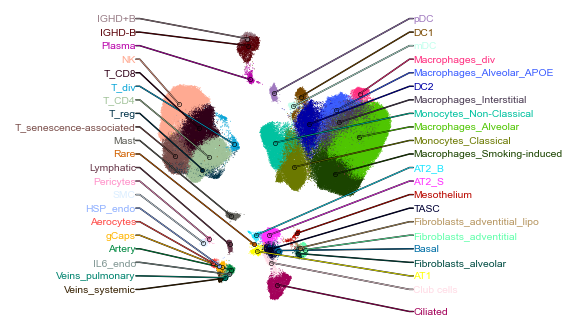

In [4]:
plot_umap_with_side_labels(lung, cell_type_key="cell_type", width_mm=58, height_mm=52, umap_width_fraction=0.75)
save_panel("Fig_1_c_lung_UMAP", png_dpi=1200)  # The PNG is used in the paper: the PDF holds one vector point per cell
plt.show()

## Fig. 1d: blood single-cell data

In [5]:
blood = umap_table_to_anndata("blood_umap.csv", "blood_cell_type_colors.csv")
blood

AnnData object with n_obs × n_vars = 93171 × 0
    obs: 'cell_type'
    uns: 'cell_type_colors'
    obsm: 'X_umap'

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


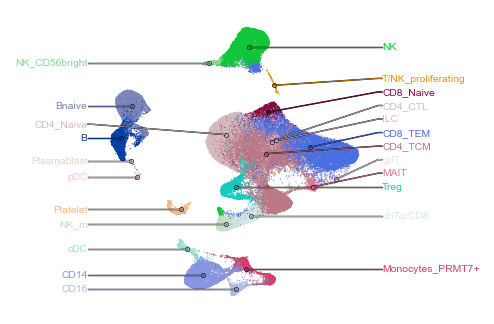

In [6]:
plot_umap_with_side_labels(blood, cell_type_key="cell_type", width_mm=70, height_mm=52, umap_width_fraction=0.66)
save_panel("Fig_1_d_blood_UMAP", png_dpi=1200)
plt.show()